# Домашнее задание 2.3 — Связанные колебания и жёсткость (🔴)

Исследую, как спектр системы двух масс определяет допустимый шаг, затухание быстрых составляющих и затраты расчёта. Сравниваю RK4, неявные трапеции из семейства Адамса–Моултона и неявный Эйлер. Последний метод позволяет проверить, как сильное численное затухание влияет одновременно на быстрый переход и медленные колебания.

Все расчёты этого ноутбука воспроизводятся независимо. Основные начальные данные $x_1(0)=1$, $x_2(0)=0$, $v_1(0)=v_2(0)=0$, $m=k_0=1$. Для отдельного спектрального опыта ниже явно задаю начальные скорости, возбуждающие самую быструю моду.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm, lu_factor, lu_solve
from scipy.optimize import brentq
from matplotlib.animation import PillowWriter
from IPython.display import Image, display

plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (9, 4.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

/usr/local/lib/python3.12/dist-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Модель и точное решение

Состояние $y=(x_1,x_2,v_1,v_2)^T$ удовлетворяет линейной системе $y'=Ay$. Все параметры далее безразмерные. Ввожу среднее и относительное смещения

$$
q=\frac{x_1+x_2}{2},\qquad r=x_1-x_2.
$$

Сложение и вычитание исходных уравнений дают

$$
\ddot q+\frac{k_0}{m}q=0,\qquad
\ddot r+\frac{2c}{m}\dot r+\frac{k_0+2k_c}{m}r=0.
$$

Общее движение масс состоит из незатухающей синфазной моды и относительного движения, на которое действует демпфер. Спектр матрицы системы имеет вид

$$
\lambda_{1,2}=\pm i\sqrt{k_0/m},\qquad
\lambda_{3,4}=-c/m\pm\sqrt{(c/m)^2-(k_0+2k_c)/m}.
$$

В качестве эталона использую $y(t)=\exp(tA)y(0)$ с вычислением матричной экспоненты. Это решение непрерывной линейной системы с погрешностью машинной арифметики. Численные методы сравниваю в одни и те же физические моменты времени. Ошибки $q$ и $r$ измеряю отдельно, чтобы быстрое относительное движение не скрывало точность медленной моды.

Полная механическая энергия и её производная равны

$$
E=\frac m2(v_1^2+v_2^2)+\frac{k_0}{2}(x_1^2+x_2^2)
+\frac{k_c}{2}(x_1-x_2)^2,\qquad
\frac{dE}{dt}=-c(v_1-v_2)^2.
$$

При $c>0$ энергия убывает за счёт относительного движения. Энергия совместной моды остаётся постоянной.

## 2. Численные методы

Для RK4 использую четыре вычисления правой части за шаг. Неявный метод трапеций относится к семейству Адамса–Моултона и имеет второй порядок.

$$
y_{n+1}=y_n+\frac h2(Ay_n+Ay_{n+1}),\qquad
(I-hA/2)y_{n+1}=(I+hA/2)y_n.
$$

На каждом шаге решаю линейную систему. На постоянном шаге факторизацию матрицы сохраняю и использую повторно. Это полностью неявный шаг без итерационного приближения корректора.

Для скалярного уравнения $u'=\lambda u$ множители за шаг равны

$$
R_{\mathrm{RK4}}(z)=1+z+z^2/2+z^3/6+z^4/24,\qquad
R_{\mathrm{тр}}(z)=\frac{1+z/2}{1-z/2},\qquad z=h\lambda.
$$

У трапеций $|R(z)|\le1$ в левой полуплоскости, но $R(z)\to-1$ вдоль отрицательной вещественной оси при $|z|\to\infty$. Очень быстро затухающая компонента при большом шаге может менять знак и сохраняться дольше, чем в точном решении.


Дополнительно использую неявный Эйлер первого порядка.

$$
(I-hA)y_{n+1}=y_n,\qquad R_{\mathrm{НЭ}}(z)=\frac{1}{1-z}.
$$

Он A-устойчив и L-устойчив. При $z\to-\infty$ множитель стремится к нулю, поэтому очень быстрые моды сильно подавляются. На мнимой оси $|R(ih\omega)|<1$, и незатухающие физические колебания получают численное затухание.

In [ ]:
def system_matrix(kc, c, m=1.0, k0=1.0):
    """Матрица для состояния (x1, x2, v1, v2)."""
    return np.array([
        [0, 0, 1, 0],
        [0, 0, 0, 1],
        [-(k0 + kc) / m, kc / m, -c / m, c / m],
        [kc / m, -(k0 + kc) / m, c / m, -c / m],
    ], dtype=float)


def exact_solution(A, y0, times):
    """Матричная экспонента с повторным использованием шага для равномерных сеток."""
    times = np.asarray(times, dtype=float)
    if len(times) > 1 and np.allclose(np.diff(times), times[1] - times[0],
                                      rtol=1e-11, atol=1e-14):
        transfer = expm((times[1] - times[0]) * A)
        values = np.empty((len(times), 4))
        values[0] = expm(times[0] * A) @ y0
        for n in range(len(times) - 1):
            values[n + 1] = transfer @ values[n]
        return values
    return np.array([expm(t * A) @ y0 for t in times])


def integrate(A, y0, times, method):
    """RK4, трапеции или неявный Эйлер. Шаг задаётся массивом времён."""
    times = np.asarray(times, dtype=float)
    values = np.full((len(times), 4), np.nan)
    values[0] = y0
    factors = {}
    n_steps = 0
    stopped = False
    eye = np.eye(4)

    for n, h in enumerate(np.diff(times)):
        y = values[n]
        if method == "RK4":
            k1 = A @ y
            k2 = A @ (y + h * k1 / 2)
            k3 = A @ (y + h * k2 / 2)
            k4 = A @ (y + h * k3)
            next_y = y + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        else:
            theta = {"Трапеции": 0.5, "Неявный Эйлер": 1.0}[method]
            # Округление ключа объединяет шаги, различающиеся только машинным шумом.
            key = round(float(h), 14)
            if key not in factors:
                factors[key] = lu_factor(eye - theta * h * A)
            rhs = y + h * (A @ y) / 2 if method == "Трапеции" else y
            next_y = lu_solve(factors[key], rhs)
        n_steps += 1
        # Явно фиксирую срыв, чтобы избежать переполнения и ложных графиков.
        if not np.isfinite(next_y).all() or np.linalg.norm(next_y, np.inf) > 1e6:
            stopped = True
            break
        values[n + 1] = next_y

    return values, {"Шагов": n_steps, "Факторизаций": len(factors),
                    "Срыв": stopped, "Вызовов RHS": (4 * n_steps if method == "RK4"
                                     else n_steps if method == "Трапеции" else 0),
                    "Решений СЛАУ": 0 if method == "RK4" else n_steps}


def time_grid(T, h):
    """Последний шаг при необходимости сокращается до T."""
    times = np.arange(int(np.floor(T / h + 1e-12)) + 1) * h
    if np.isclose(times[-1], T, rtol=0, atol=1e-12):
        times[-1] = T
    else:
        times = np.append(times, T)
    return times


def modes(values):
    return (values[:, 0] + values[:, 1]) / 2, values[:, 0] - values[:, 1]


def energy(values, kc, m=1.0, k0=1.0):
    x1, x2, v1, v2 = values.T
    return (m * (v1**2 + v2**2) / 2 + k0 * (x1**2 + x2**2) / 2
            + kc * (x1 - x2)**2 / 2)


def stability_function(z, method):
    if method == "RK4":
        return 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24
    if method == "Трапеции":
        return (1 + z / 2) / (1 - z / 2)
    if method == "Неявный Эйлер":
        return 1 / (1 - z)
    raise ValueError("Неизвестный метод")


Y0 = np.array([1.0, 0.0, 0.0, 0.0])
METHODS = ["RK4", "Трапеции"]

## 3. Спектр и граница устойчивости RK4

Сравниваю четыре набора параметров. В первых двух относительная мода колебательная, в двух остальных — апериодическая. Под $h_{\mathrm{RK4}}$ понимаю первый выход спектра $h\lambda_j$ за область абсолютной устойчивости RK4 при увеличении положительного шага.

Для чисто мнимой моды ограничение равно $h\omega\le2\sqrt2$, а для отрицательной вещественной — $h|\lambda|\lesssim2.78529356$. В таблице вычисляю границу численно для каждой моды и беру минимум. Отношение $\max|\lambda|/\min|\lambda|$ характеризует разделение масштабов, но само по себе не определяет вид переходного процесса.

In [3]:
def rk4_step_limit(A):
    limits = []
    for lam in np.linalg.eigvals(A):
        scale = abs(lam)
        root = brentq(lambda s: abs(stability_function(s * lam / scale, "RK4"))**2 - 1,
                      0.1, 10)
        limits.append(root / scale)
    return min(limits)


cases = [
    ("слабая связь", 0.05, 0.0),
    ("жёсткая пружина", 499.5, 0.0),
    ("сильное затухание", 499.5, 50.0),
    ("большой демпфер", 499.5, 500.0),
]
spectrum_rows = []
for name, kc, c in cases:
    A_case = system_matrix(kc, c)
    spectrum = np.sort_complex(np.linalg.eigvals(A_case))
    spectrum_rows.append({
        "Режим": name, "kc": kc, "c": c,
        "Спектр": ", ".join(f"{z.real:.3f}{z.imag:+.3f}i" for z in spectrum),
        "max |λ| / min |λ|": max(abs(spectrum)) / min(abs(spectrum)),
        "h_RK4": rk4_step_limit(A_case),
    })
display(pd.DataFrame(spectrum_rows).style.format({"max |λ| / min |λ|": "{:.2f}", "h_RK4": "{:.6f}"}))

,Режим,kc,c,Спектр,max |λ| / min |λ|,h_RK4
0,слабая связь,0.050000,0.000000,"-0.000-1.000i, -0.000+1.000i, 0.000-1.049i, 0.000+1.049i",1.05,2.696799
1,жёсткая пружина,499.500000,0.000000,"-0.000-1.000i, -0.000+1.000i, 0.000-31.623i, 0.000+31.623i",31.62,0.089443
2,сильное затухание,499.500000,50.000000,"-88.730+0.000i, -11.270+0.000i, -0.000-1.000i, -0.000+1.000i",88.73,0.031391
3,большой демпфер,499.500000,500.000000,"-998.999+0.000i, -1.001+0.000i, -0.000-1.000i, -0.000+1.000i",999.00,0.002788


## 4. Затухание быстрого процесса на одном шаге

Для $k_c=499.5$, $c=500$ относительные показатели близки к $\lambda_s=-1.001$ и $\lambda_f=-998.999$. Большой демпфер создаёт очень быструю моду, но одновременно делает вторую относительную моду медленнее, чем при $c=50$. Поэтому увеличение $c$ не означает более быстрое исчезновение всего относительного движения.

На графиках сравниваю численные множители с точным $\exp(h\lambda_f)$. Знак множителя имеет значение. У трапеций при $h|\lambda_f|>2$ возникает чередование знаков.

λ_fast = -998.998997995, λ_slow = -1.001002005


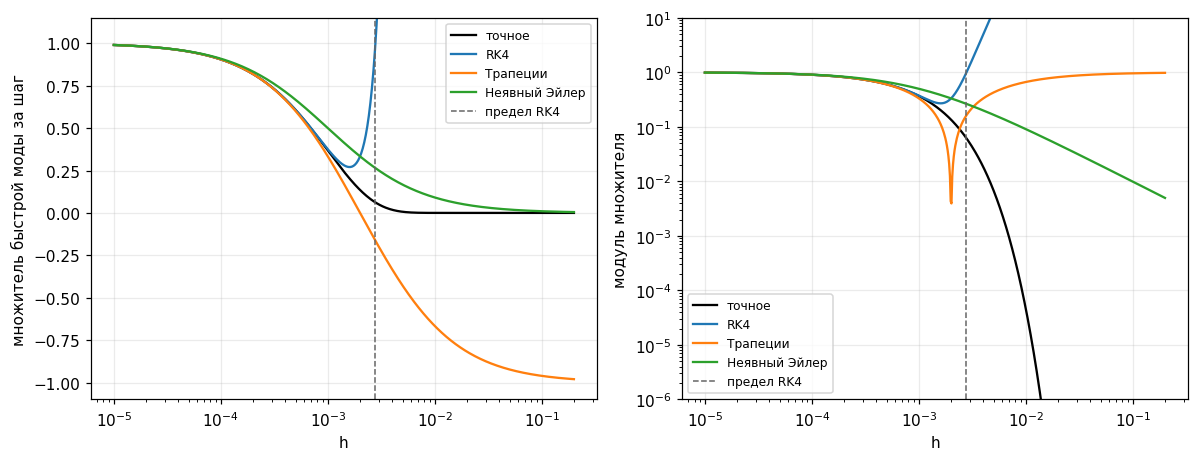

,h,exp(hλ_fast),RK4,Трапеции,Неявный Эйлер
0,0.001,0.368248,0.375334,0.333778,0.50025
1,0.002,0.135606,0.332668,0.000500752,0.333556
2,0.01,4.58567e-05,289.744,-0.666388,0.0909919
3,0.05,2.02774e-22,239803,-0.923003,0.0196271


In [4]:
KC, C = 499.5, 500.0
A = system_matrix(KC, C)
relative_roots = np.sort(np.roots([1, 2 * C, 1 + 2 * KC]))
lambda_fast, lambda_slow = relative_roots
print(f"λ_fast = {lambda_fast:.9f}, λ_slow = {lambda_slow:.9f}")

h_axis = np.geomspace(1e-5, 0.2, 600)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].plot(h_axis, np.exp(h_axis * lambda_fast), color="black", label="точное")
axes[1].loglog(h_axis, np.exp(h_axis * lambda_fast), color="black", label="точное")
for method in METHODS + ["Неявный Эйлер"]:
    factor = stability_function(h_axis * lambda_fast, method)
    axes[0].plot(h_axis, factor, label=method)
    axes[1].loglog(h_axis, abs(factor), label=method)
axes[0].set_xscale("log")
axes[0].set_ylim(-1.1, 1.15)
axes[0].set_ylabel("множитель быстрой моды за шаг")
axes[1].set_ylim(1e-6, 10)
axes[1].set_ylabel("модуль множителя")
for ax in axes:
    ax.axvline(rk4_step_limit(A), color="0.4", ls="--", lw=1, label="предел RK4")
    ax.set_xlabel("h")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

factor_rows = []
for h in [0.001, 0.002, 0.01, 0.05]:
    row = {"h": h, "exp(hλ_fast)": np.exp(h * lambda_fast)}
    row.update({method: stability_function(h * lambda_fast, method)
                for method in METHODS + ["Неявный Эйлер"]})
    factor_rows.append(row)
display(pd.DataFrame(factor_rows).style.format("{:.6g}"))

## 5. Устойчивый, но неверный переходный процесс

Чтобы увидеть именно самую быструю моду, задаю $q(0)=0.5$, $\dot q(0)=0$, $r(0)=1$ и $\dot r(0)=\lambda_f$. Тогда

$$
q(t)=0.5\cos t,\qquad r(t)=e^{\lambda_f t}.
$$

В исходных переменных $x_1(0)=1$, $x_2(0)=0$, $v_1(0)=\lambda_f/2$, $v_2(0)=-\lambda_f/2$. Большие начальные скорости в этом опыте выбраны для выделения моды в линейной модели. Сравниваю узлы с $h=0.001$ и $0.01$. Между узлами численные значения на графике соединены прямыми отрезками.

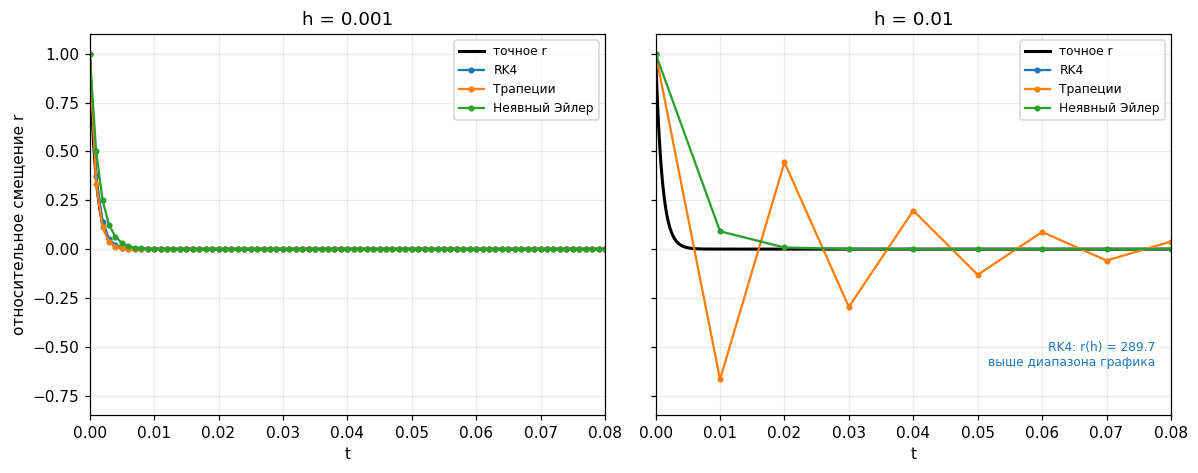

In [5]:
y_fast = np.array([1.0, 0.0, lambda_fast / 2, -lambda_fast / 2])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, h in zip(axes, [0.001, 0.01]):
    times = time_grid(0.08, h)
    dense = np.linspace(0, 0.08, 1000)
    ax.plot(dense, np.exp(lambda_fast * dense), color="black", lw=2, label="точное r")
    for method in METHODS + ["Неявный Эйлер"]:
        values, info = integrate(A, y_fast, times, method)
        _, r = modes(values)
        ax.plot(times, r, ".-", label=method)
        if method == "RK4" and h == 0.01:
            ax.text(0.97, 0.13, f"RK4: r(h) = {r[1]:.1f}\nвыше диапазона графика",
                    transform=ax.transAxes, ha="right", fontsize=8, color="C0")
    ax.set_xlim(0, 0.08)
    ax.set_ylim(-0.85, 1.1)
    ax.set_title(f"h = {h:g}")
    ax.set_xlabel("t")
    ax.legend(fontsize=8)
axes[0].set_ylabel("относительное смещение r")
fig.tight_layout()
plt.show()

При $h=0.01$ точная быстрая мода уже за первый шаг уменьшается примерно до $4.59\cdot10^{-5}$. Трапеции вместо этого дают около $-0.6664$. Расчёт устойчив, но предсказывает заметные знакопеременные колебания в апериодическом переходе. Неявный Эйлер сохраняет знак, но даёт около $0.0910$, поэтому грубый шаг и у него не воспроизводит скорость физического затухания. RK4 на этом шаге неустойчив.

При $h=0.001$ все методы устойчивы, однако ошибка первого слоя у RK4 и неявного Эйлера всё ещё заметна. Устойчивость задаёт лишь допустимость шага. Чтобы разрешить форму быстрого перехода, шаг должен быть существенно меньше времени $1/|\lambda_f|$.

## 6. Точность медленного движения и сгущение шага

Возвращаю основные начальные условия с нулевыми скоростями. При $T=20$ отдельно измеряю максимальную ошибку $q$ на всём интервале, максимальную ошибку $r$ в переходе $0\le t\le0.1$ и ошибку относительного движения позднее, при $t\ge1$. У неустойчивого расчёта ошибки за полный интервал не указываю.

Для проверки порядка отдельно беру систему с $c=50$ при том же $k_c=499.5$ и шаги $h=0.02,\ 0.01,\ 0.005$. Они устойчивы для RK4 и позволяют измерить его ошибку до влияния округления. Оценка $p=\log_2(E_h/E_{h/2})$ относится к ошибке медленного смещения на $[0,20]$. В этом опыте эталон $q_*(t)=0.5\cos t$ вычисляю напрямую.

,Метод,h,Срыв,E_q,"E_r, t≤0.1","E_r, t≥1"
0,RK4,0.0500,True,nan,nan,nan
1,Трапеции,0.0500,False,1.899e-03,9.158e-04,2.789e-04
2,Неявный Эйлер,0.0500,False,1.877e-01,2.198e-03,9.028e-03
3,RK4,0.0100,True,nan,nan,nan
4,Трапеции,0.0100,False,7.607e-05,6.684e-04,3.075e-06
5,Неявный Эйлер,0.0100,False,4.501e-02,4.508e-04,1.835e-03
6,RK4,0.0020,False,1.218e-12,1.977e-04,5.235e-14
7,Трапеции,0.0020,False,3.043e-06,1.355e-04,1.230e-07
8,Неявный Эйлер,0.0020,False,9.349e-03,1.965e-04,3.683e-04
9,RK4,0.0010,False,7.622e-14,7.107e-06,1.421e-14


,Метод,h,E_q,E_q(h/2),p по E_q
0,RK4,0.020,1.208e-08,7.579e-10,3.994
1,RK4,0.010,7.579e-10,4.746e-11,3.997
2,Трапеции,0.020,3.043e-04,7.607e-05,2.000
3,Трапеции,0.010,7.607e-05,1.902e-05,2.000
4,Неявный Эйлер,0.020,8.594e-02,4.501e-02,0.933
5,Неявный Эйлер,0.010,4.501e-02,2.304e-02,0.966


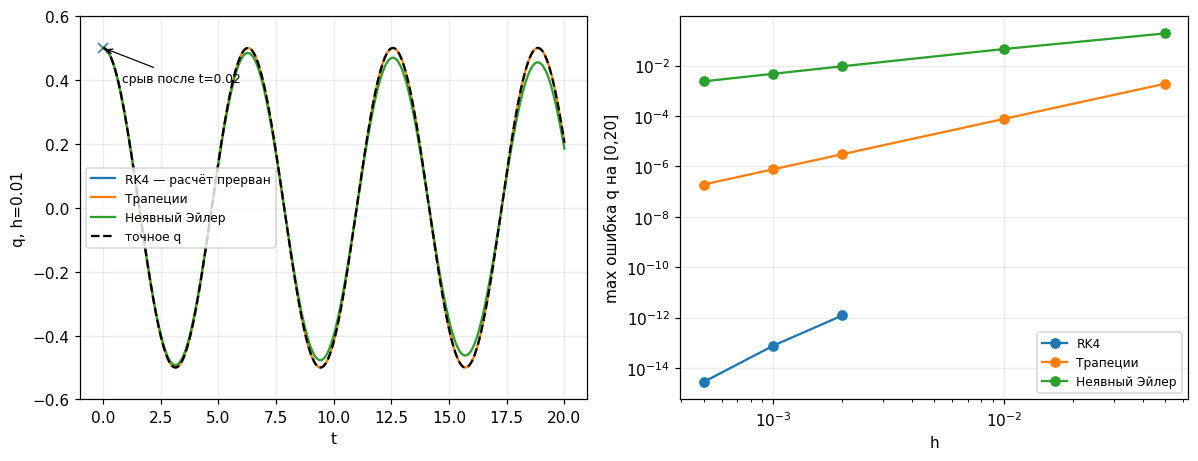

In [6]:
T = 20.0
red_runs = {}
accuracy_rows = []
for h in [0.05, 0.01, 0.002, 0.001, 0.0005]:
    times = time_grid(T, h)
    _, r_ref = modes(exact_solution(A, Y0, times))
    q_ref = 0.5 * np.cos(times)
    for method in METHODS + ["Неявный Эйлер"]:
        values, info = integrate(A, Y0, times, method)
        red_runs[(method, h)] = times, values, info
        q, r = modes(values)
        accuracy_rows.append({
            "Метод": method, "h": h, "Срыв": info["Срыв"],
            "E_q": np.nan if info["Срыв"] else np.max(abs(q - q_ref)),
            "E_r, t≤0.1": np.nan if info["Срыв"] else np.max(abs(r[times <= 0.1] - r_ref[times <= 0.1])),
            "E_r, t≥1": np.nan if info["Срыв"] else np.max(abs(r[times >= 1] - r_ref[times >= 1])),
        })
accuracy = pd.DataFrame(accuracy_rows)
display(accuracy.style.format({"h": "{:.4f}", "E_q": "{:.3e}",
                              "E_r, t≤0.1": "{:.3e}", "E_r, t≥1": "{:.3e}"}))
order_rows = []
A_order = system_matrix(KC, 50.0)
for method in METHODS + ["Неявный Эйлер"]:
    mode_errors = {}
    for h in [0.02, 0.01, 0.005]:
        times = time_grid(T, h)
        values, _ = integrate(A_order, Y0, times, method)
        q, _ = modes(values)
        mode_errors[h] = np.max(abs(q - 0.5 * np.cos(times)))
    for h in [0.02, 0.01]:
        order_rows.append({"Метод": method, "h": h, "E_q": mode_errors[h],
                          "E_q(h/2)": mode_errors[h / 2],
                          "p по E_q": np.log2(mode_errors[h] / mode_errors[h / 2])})
display(pd.DataFrame(order_rows).style.format({"h": "{:.3f}", "E_q": "{:.3e}",
                                              "E_q(h/2)": "{:.3e}", "p по E_q": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for method in METHODS + ["Неявный Эйлер"]:
    times, values, info = red_runs[(method, 0.01)]
    q, _ = modes(values)
    label = f"{method} — расчёт прерван" if info["Срыв"] else method
    axes[0].plot(times, q, label=label)
    if info["Срыв"]:
        last = np.flatnonzero(np.isfinite(q))[-1]
        axes[0].plot(times[last], q[last], "x", color="C0", ms=7)
        axes[0].annotate(f"срыв после t={times[last]:g}", (times[last], q[last]),
                         xytext=(12, -22), textcoords="offset points", fontsize=8,
                         arrowprops={"arrowstyle": "->", "lw": 0.8})
    good = accuracy[(accuracy["Метод"] == method) & ~accuracy["Срыв"]]
    axes[1].loglog(good["h"], good["E_q"], "o-", label=method)
dense = np.linspace(0, T, 1000)
axes[0].plot(dense, 0.5 * np.cos(dense), "k--", lw=1.5, label="точное q")
axes[0].set_ylim(-0.6, 0.6)
axes[0].set_xlabel("t")
axes[0].set_ylabel("q, h=0.01")
axes[1].set_xlabel("h")
axes[1].set_ylabel("max ошибка q на [0,20]")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

У трапеций при чисто мнимой моде модуль множителя равен единице. Амплитуда $q$ сохраняется, но частота равна $2\arctan(h/2)/h$ вместо 1. Неявный Эйлер дополнительно уменьшает амплитуду. Поэтому способность подавлять быстрые моды не гарантирует точности незатухающих медленных колебаний.

В проверке порядка при $c=50$ получаются значения около 4 для RK4, 2 для трапеций и 1 для неявного Эйлера. У системы с $c=500$ устойчивость требует настолько малых шагов RK4, что ошибка медленной моды на самом мелком шаге составляет несколько единиц $10^{-15}$. Здесь влияние округления становится существенным, поэтому оценку порядка по таким ошибкам нужно проверять на более крупных устойчивых шагах. Ошибка относительной моды на тех же шагах ещё заметна и убывает.

## 7. Ограничения на шаг и вычислительные затраты

Задаю общую практическую цель $\max_{[0,20]}|q-q_*|<10^{-3}$ и устойчивость полного состояния. Для каждого набора параметров и метода перебираю одну и ту же убывающую сетку шагов. Беру первый, то есть самый крупный из проверенных шагов, удовлетворяющий обоим условиям. Это выбор на конечном наборе, а не поиск оптимального шага.

Для $q$ у линейных методов можно независимо проверить ошибку по скалярной моде $q_n=\tfrac12\mathrm{Re}\,[R(ih)^n]$. Затем запускаю полную систему на выбранном шаге. Цель этого опыта — точность медленного движения. Правильность быстрого перехода дополнительно проверена в разделах 4–6.

Счётчики отражают выполненные операции. Для RK4 это четыре вызова $Ay$ за шаг. Для трапеций — одно умножение $Ay$, одно решение СЛАУ за шаг и сохранённая факторизация. Неявному Эйлеру умножение $Ay$ для правой части не требуется. Время измеряю медианой трёх запусков полной системы, включая подготовку факторизации. Эти времена зависят от компьютера и не переносятся напрямую на большие системы.

In [7]:
candidate_h = [0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001, 0.0005, 0.0002, 0.0001]
cost_rows = []
for name, kc, c in cases:
    A_case = system_matrix(kc, c)
    spectrum = np.linalg.eigvals(A_case)
    for method in METHODS + ["Неявный Эйлер"]:
        chosen = None
        for h in candidate_h:
            if max(abs(stability_function(h * spectrum, method))) > 1 + 1e-12:
                continue
            times = time_grid(T, h)
            q_num = 0.5 * np.real(stability_function(1j * h, method)**np.arange(len(times)))
            error = np.max(abs(q_num - 0.5 * np.cos(times)))
            if error < 1e-3:
                chosen = h
                break
        if chosen is None:
            raise RuntimeError("Нужно расширить список шагов")
        durations = []
        for _ in range(3):
            started = perf_counter()
            values, info = integrate(A_case, Y0, times, method)
            durations.append(perf_counter() - started)
        q, _ = modes(values)
        full_error = np.max(abs(q - 0.5 * np.cos(times)))
        assert not info["Срыв"] and full_error < 1e-3
        cost_rows.append({"Режим": name, "Метод": method, "h": chosen,
                          "E_q": full_error, "Шагов": info["Шагов"],
                          "RHS": info["Вызовов RHS"], "СЛАУ": info["Решений СЛАУ"],
                          "LU": info["Факторизаций"],
                          "Время, с": np.median(durations)})
costs = pd.DataFrame(cost_rows)
display(costs.style.format({"h": "{:.4g}", "E_q": "{:.3e}", "Время, с": "{:.4f}"}))

,Режим,Метод,h,E_q,Шагов,RHS,СЛАУ,LU,"Время, с"
0,слабая связь,RK4,0.1,7.298e-06,200,800,0,0,0.0034
1,слабая связь,Трапеции,0.02,3.043e-04,1000,1000,1000,1,0.0142
2,слабая связь,Неявный Эйлер,0.0002,9.429e-04,100000,0,100000,1,0.6938
3,жёсткая пружина,RK4,0.05,4.662e-07,400,1600,0,0,0.0060
4,жёсткая пружина,Трапеции,0.02,3.043e-04,1000,1000,1000,1,0.0096
5,жёсткая пружина,Неявный Эйлер,0.0002,9.429e-04,100000,0,100000,1,0.6884
6,сильное затухание,RK4,0.02,1.208e-08,1000,4000,0,0,0.0152
7,сильное затухание,Трапеции,0.02,3.043e-04,1000,1000,1000,1,0.0097
8,сильное затухание,Неявный Эйлер,0.0002,9.429e-04,100000,0,100000,1,0.6623
9,большой демпфер,RK4,0.002,1.218e-12,10000,40000,0,0,0.1509


## 8. Выводы

Спектр ограничивает RK4 даже тогда, когда интерес представляет только медленное движение. При увеличении жёсткости пружины растёт колебательная частота и уменьшается допустимый шаг. При очень большом демпфировании появляется отрицательное собственное значение большого модуля, и требование устойчивости становится ещё строже. Это видно по выбранным шагам и числу шагов в таблице затрат.

Трапеции устойчивы на всех рассмотренных шагах, но на большом отрицательном $h\lambda_f$ сохраняют лишнюю быструю составляющую с чередованием знака. В выделенном спектральном опыте при $h=0.01$ этот дефект виден уже на первом слое. Для точного воспроизведения быстрого перехода нужна проверка его временного масштаба и сгущение шага.

Неявный Эйлер подавляет быстрые составляющие, но его первый порядок и численное затухание медленной моды требуют малого шага для цели по $q$. Поэтому в этой задаче L-устойчивость сама по себе не означает меньшие затраты при одинаковой точности медленного движения.

После физического затухания быстрых составляющих шаг трапеций можно выбирать по точности медленной моды, если остаточные быстрые компоненты уже малы. При грубом шаге в самом начале расчёта A-устойчивость недостаточна. Выбор шага зависит от того, требуется ли разрешить переходный процесс или только последующее движение, и от допуска на фазовую и амплитудную ошибки.